# Réponses API et visualisation des segmentations

Ce notebook envoie des images à l'API de segmentation du projet, conserve les réponses JSON complètes en mémoire et affiche les masques retournés. Il ne contient pas de résultats fictifs : exécutez les cellules pour obtenir vos propres réponses.

**Prérequis :** installer les dépendances de `requirements.txt` dans le noyau Jupyter. En mode local, démarrer séparément l'API sur `http://localhost:8000/segment`. En mode Hugging Face, renseigner `token` dans `.env` ou `HF_TOKEN` dans l'environnement ; ne jamais écrire le jeton dans le notebook. Les appels distants peuvent être soumis à des limites ou à des frais.

In [2]:
import base64
import io
import json
import os
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import requests
from dotenv import load_dotenv
from PIL import Image

from segmentation import CLASS_MAPPING

## Configuration

Exécutez le notebook depuis la racine du dépôt. `api_local` dans `.env` sélectionne l'API locale ; sinon l'API Hugging Face est utilisée. Modifiez le dossier ou la limite selon vos besoins.

In [3]:
load_dotenv()
image_dir = Path('assets') / 'IMG'
max_images = 3
pause_secondes = 1
api_local = os.getenv('api_local', 'false').strip().lower() == 'true'
api_url = ('http://localhost:8000/segment' if api_local else
           'https://router.huggingface.co/hf-inference/models/sayeed99/segformer_b3_clothes')
api_token = os.getenv('HF_TOKEN') or os.getenv('token')

if max_images < 1:
    raise ValueError('max_images doit être supérieur à zéro.')
if not image_dir.is_dir():
    raise FileNotFoundError(f'Dossier introuvable : {image_dir}')
image_paths = sorted(p for p in image_dir.iterdir()
                     if p.is_file() and p.suffix.lower() in {'.jpg', '.jpeg', '.png'})[:max_images]
if not image_paths:
    raise ValueError(f'Aucune image JPEG ou PNG dans {image_dir}.')
if not api_local and not api_token:
    raise ValueError('Définissez HF_TOKEN ou token dans .env pour utiliser Hugging Face.')
print(f"Mode : {'local' if api_local else 'Hugging Face'} ; {len(image_paths)} image(s)")
print('\n'.join(str(path) for path in image_paths))

Mode : local ; 3 image(s)
assets\IMG\image_0.png
assets\IMG\image_1.png
assets\IMG\image_2.png


## Requêtes et réponses API

Chaque réponse complète est conservée dans `reponses`, associée à son image et à son statut HTTP. Les masques encodés en base64 sont abrégés uniquement dans l'affichage pour garder le notebook lisible. Une erreur HTTP, une réponse inattendue ou un masque invalide arrête l'exécution avec un message explicite.

In [4]:
def interroger_api(image_path):
    content_type = 'image/png' if image_path.suffix.lower() == '.png' else 'image/jpeg'
    image_data = image_path.read_bytes()
    if api_local:
        response = requests.post(api_url, files={'file': (image_path.name, image_data, content_type)}, timeout=120)
    else:
        response = requests.post(api_url, headers={'Authorization': f'Bearer {api_token}',
                                                    'Content-Type': content_type},
                                 data=image_data, timeout=120)
    response.raise_for_status()
    payload = response.json()
    if not isinstance(payload, list):
        raise ValueError(f'Réponse API inattendue pour {image_path} : {payload}')
    for item in payload:
        if not isinstance(item, dict) or not isinstance(item.get('label'), str) or not isinstance(item.get('mask'), str):
            raise ValueError(f'Entrée de segmentation invalide pour {image_path} : {item}')
        if item['label'] not in CLASS_MAPPING:
            raise ValueError(f"Classe inconnue pour {image_path} : {item['label']}")
    return {'image': image_path, 'statut': response.status_code, 'resultats': payload}

reponses = []
for index, image_path in enumerate(image_paths):
    if index:
        time.sleep(pause_secondes)
    reponses.append(interroger_api(image_path))
    print(f"{image_path.name} : HTTP {reponses[-1]['statut']}, {len(reponses[-1]['resultats'])} masque(s)")

image_0.png : HTTP 200, 11 masque(s)
image_1.png : HTTP 200, 12 masque(s)
image_2.png : HTTP 200, 9 masque(s)


In [5]:
for reponse in reponses:
    resume = [{**item, 'mask': f"<base64 : {len(item['mask'])} caractères>"}
              for item in reponse['resultats']]
    print(f"\n{reponse['image'].name} — HTTP {reponse['statut']}")
    print(json.dumps(resume, ensure_ascii=False, indent=2))


image_0.png — HTTP 200
[
  {
    "label": "Background",
    "score": null,
    "mask": "<base64 : 3132 caractères>"
  },
  {
    "label": "Hair",
    "score": null,
    "mask": "<base64 : 1264 caractères>"
  },
  {
    "label": "Upper-clothes",
    "score": null,
    "mask": "<base64 : 2124 caractères>"
  },
  {
    "label": "Pants",
    "score": null,
    "mask": "<base64 : 1192 caractères>"
  },
  {
    "label": "Left-shoe",
    "score": null,
    "mask": "<base64 : 1020 caractères>"
  },
  {
    "label": "Right-shoe",
    "score": null,
    "mask": "<base64 : 828 caractères>"
  },
  {
    "label": "Face",
    "score": null,
    "mask": "<base64 : 828 caractères>"
  },
  {
    "label": "Left-leg",
    "score": null,
    "mask": "<base64 : 572 caractères>"
  },
  {
    "label": "Right-leg",
    "score": null,
    "mask": "<base64 : 524 caractères>"
  },
  {
    "label": "Right-arm",
    "score": null,
    "mask": "<base64 : 516 caractères>"
  },
  {
    "label": "Bag",
    "score": n

## Visualisation des résultats

Les masques sont décodés et redimensionnés à la taille de l'image par interpolation au plus proche. La superposition utilise une couleur par classe. En cas de chevauchement, le dernier masque non-fond de la réponse est visible ; les pourcentages du graphique sont calculés indépendamment pour chaque masque et peuvent donc dépasser 100 % au total. Le fond n'est pas superposé.

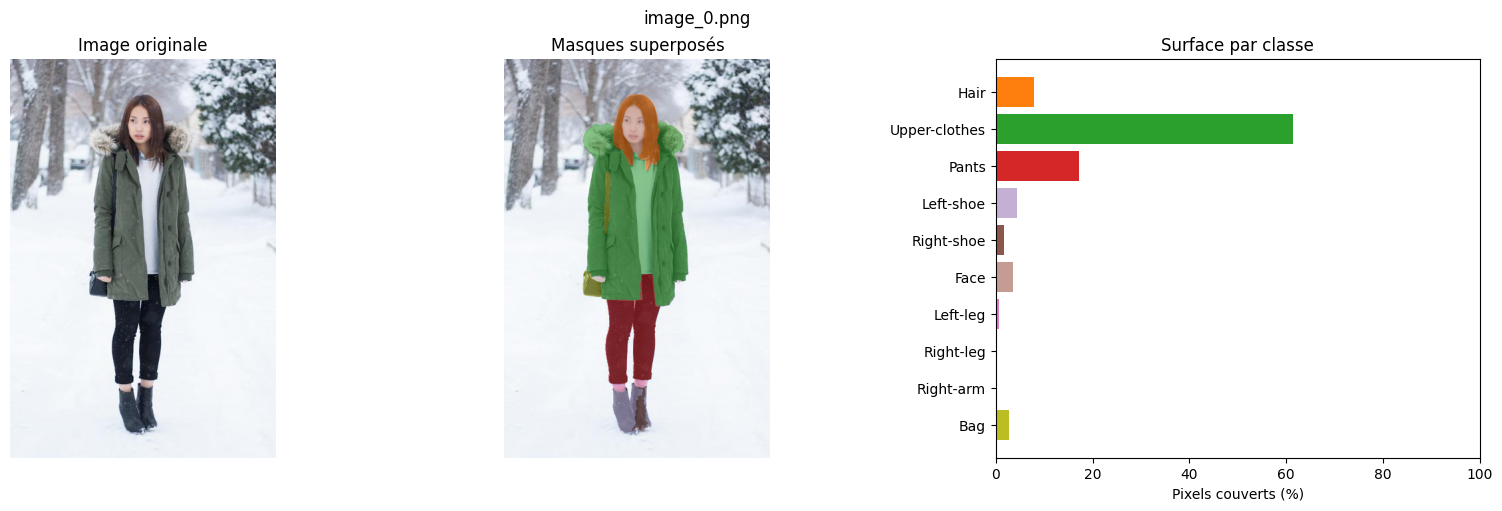

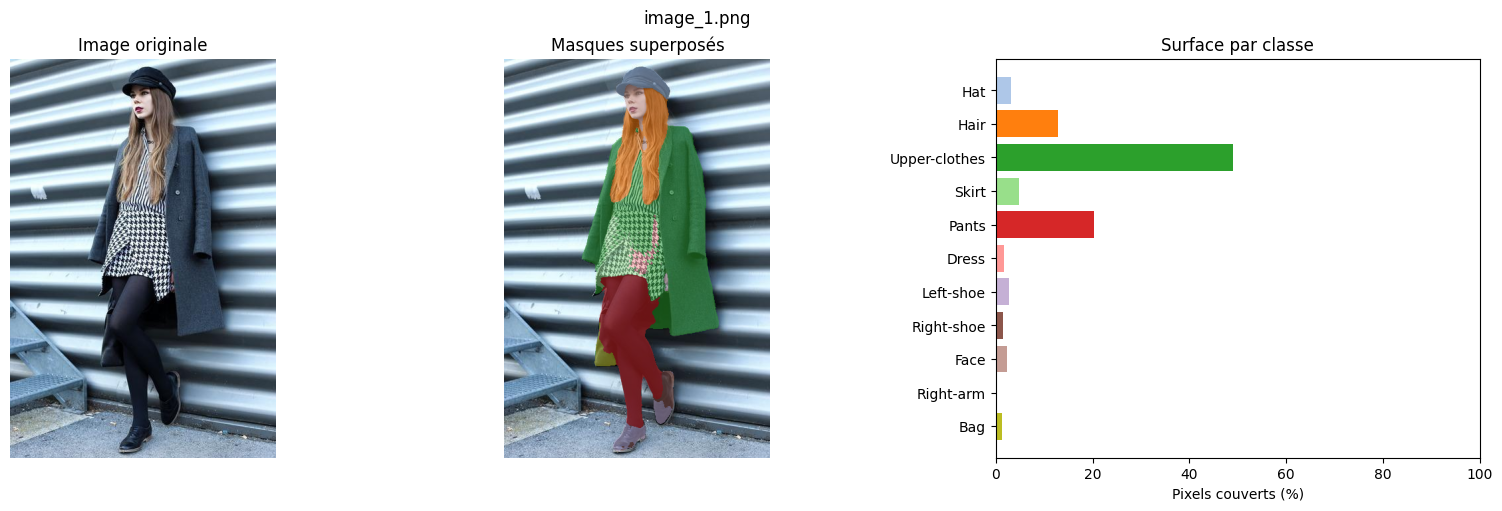

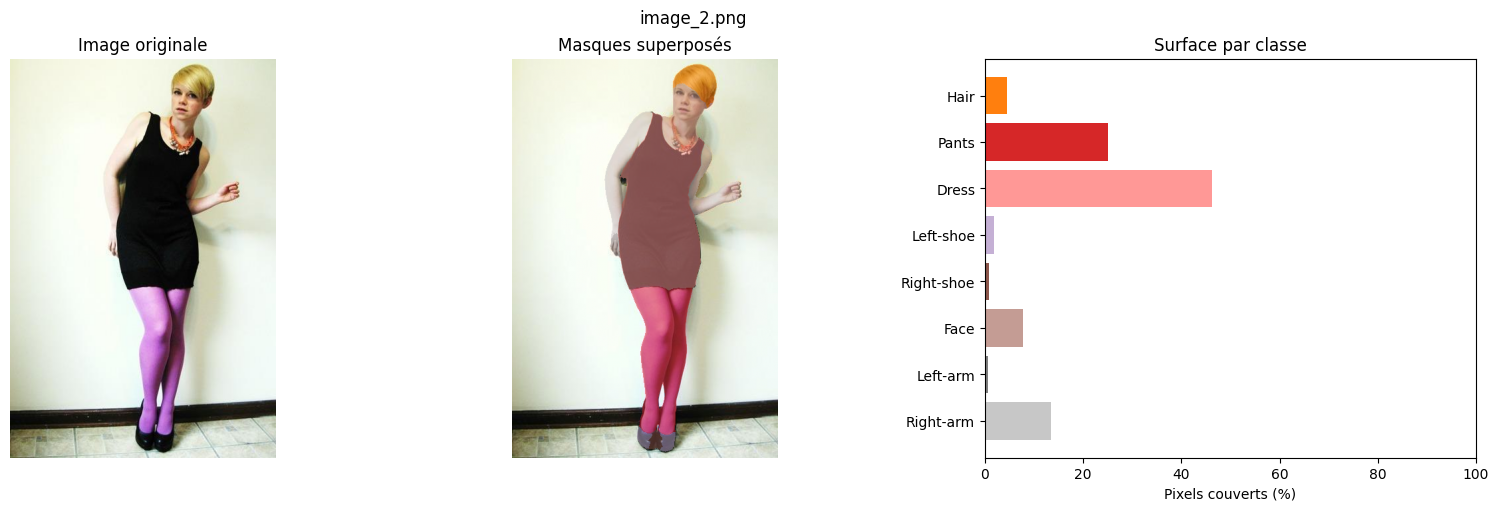

In [7]:
def decoder_masque(mask_base64, taille):
    donnees = base64.b64decode(mask_base64, validate=True)
    with Image.open(io.BytesIO(donnees)) as masque:
        masque = masque.convert('L').resize(taille, resample=Image.Resampling.NEAREST)
        return np.asarray(masque) > 0

def afficher_resultat(reponse):
    with Image.open(reponse['image']) as source:
        image = np.asarray(source.convert('RGB'))
    hauteur, largeur = image.shape[:2]
    superposition = image.astype(float) / 255
    palette = plt.get_cmap('tab20')
    etiquettes, surfaces, couleurs = [], [], []
    pixels_non_background = np.zeros((hauteur, largeur), dtype=bool)
    for resultat in reponse['resultats']:
        label = resultat['label']
        if label == 'Background':
            continue
        masque = decoder_masque(resultat['mask'], (largeur, hauteur))
        couleur = palette(CLASS_MAPPING[label] % 20)[:3]
        etiquettes.append(label)
        surfaces.append(np.count_nonzero(masque))
        pixels_non_background |= masque
        couleurs.append(couleur)
        superposition[masque] = 0.5 * (image[masque] / 255) + 0.5 * np.asarray(couleur)
    total_pixels_non_background = np.count_nonzero(pixels_non_background)
    proportions = [
        100 * surface / total_pixels_non_background if total_pixels_non_background else 0
        for surface in surfaces
    ]

    fig, axes = plt.subplots(1, 3, figsize=(16, 5), constrained_layout=True)
    axes[0].imshow(image)
    axes[0].set_title('Image originale')
    axes[1].imshow(superposition)
    axes[1].set_title('Masques superposés')
    for ax in axes[:2]:
        ax.axis('off')
    axes[2].barh(etiquettes, proportions, color=couleurs)
    axes[2].set_xlabel('Pixels couverts (%)')
    axes[2].set_xlim(0, 100)
    axes[2].set_title('Surface par classe')
    axes[2].invert_yaxis()
    fig.suptitle(reponse['image'].name)
    plt.show()

for reponse in reponses:
    afficher_resultat(reponse)